<a href="https://colab.research.google.com/github/evievujovic/skills-introduction-to-github/blob/main/KV5056_W1_EvieVujovic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Python: 3.12.11
0S: Linux-6.6.97+-x86_64-with-glibc2.35


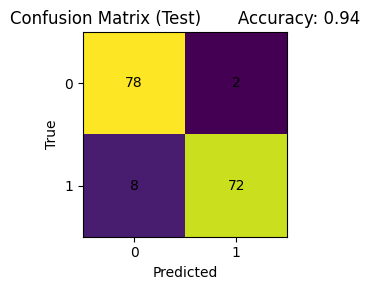

In [31]:
import sys, platform
print ("Python:", sys.version.split()[0])
print ("0S:", platform.platform())

!pip -q install --upgrade pip
!pip -q install numpy pandas scikit-learn matplotlib

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
np.random.seed(42)

X_num,  y = make_classification(
    n_samples=800, n_features=2, n_informative=2, n_redundant=0,
    class_sep=1.2, random_state=42
)
tmp = pd.DataFrame(X_num, columns=["num0","num1"])

df = pd.DataFrame({
    "age":     np.clip(np.round(tmp["num0"]*10 + 40), 18, 80).astype(int
        ),
    "income": np.round(np.exp(tmp["num1"]+10)/1e4, 2),
    "city": np.random.choice(["Newcastle", "Durham", "Leeds", "Manchester"], size=len(tmp)),
    "channel":np.random.choice(["web","store", "phone"], size=len(tmp), p=[0.6,0.3,0.1]),
     "bought": y.astype(int)
})

X = df.drop(columns=["bought"])
y = df["bought"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_feats = ["age", "income"]
cat_feats= ["city", "channel"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_feats),
    ("cat", categorical_pipe, cat_feats)
])

clf = Pipeline ([
  ("prep", preprocess),
  ("model", LogisticRegression(max_iter=1000))
])
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

cm = confusion_matrix(y_test, pred, labels=[0,1])
acc = accuracy_score(y_test, pred)

fig, ax = plt.subplots(figsize=(4,3))
im = ax.imshow(cm)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(["0","1"]); ax.set_yticklabels(["0","1"])
ax.set_title(f"Confusion Matrix (Test)       Accuracy: {acc:.2f}")
for i in range(cm.shape[0]):
  for j in range(cm.shape[1]):
    ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.show()

